In [28]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

In [29]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [30]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [31]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

In [33]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [35]:
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

Minimum: 0.0
Maximum: 0.00392156862745098


In [37]:
# Reload original MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize exactly once
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# One-hot encode labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# Verify normalization
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Minimum: 0.0
Maximum: 1.0
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


In [39]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 442us/step - accuracy: 0.9885 - loss: 0.0372
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 451us/step - accuracy: 0.9910 - loss: 0.0278
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 450us/step - accuracy: 0.9934 - loss: 0.0219
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 435us/step - accuracy: 0.9945 - loss: 0.0177
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 436us/step - accuracy: 0.9950 - loss: 0.0159


In [41]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 464us/step - accuracy: 0.9779 - loss: 0.0855
Test Loss: 0.08553272485733032
Test Accuracy: 97.79000282287598 %


In [43]:
model.save("mnist_digit_model.keras")

In [44]:
import os

print(os.path.exists("mnist_digit_model.keras"))

True


In [45]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load saved model
loaded_model = tf.keras.models.load_model(
    "mnist_digit_model.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


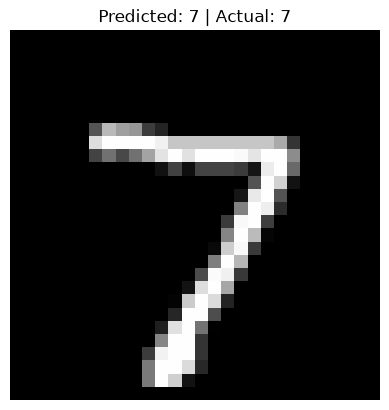

Predicted digit: 7
Actual digit: 7
Confidence: 100.0 %


In [46]:
# Select an image from test dataset
index = 0

# Get the image
image = x_test[index]

# Make prediction
prediction = loaded_model.predict(
    image.reshape(1, 28, 28),
    verbose=0
)

# Find predicted digit
predicted_digit = np.argmax(prediction)

# Find actual digit
actual_digit = np.argmax(y_test[index])

# Display image
plt.imshow(image, cmap="gray")
plt.title(
    f"Predicted: {predicted_digit} | Actual: {actual_digit}"
)
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Actual digit:", actual_digit)
print("Confidence:", round(np.max(prediction) * 100, 2), "%")

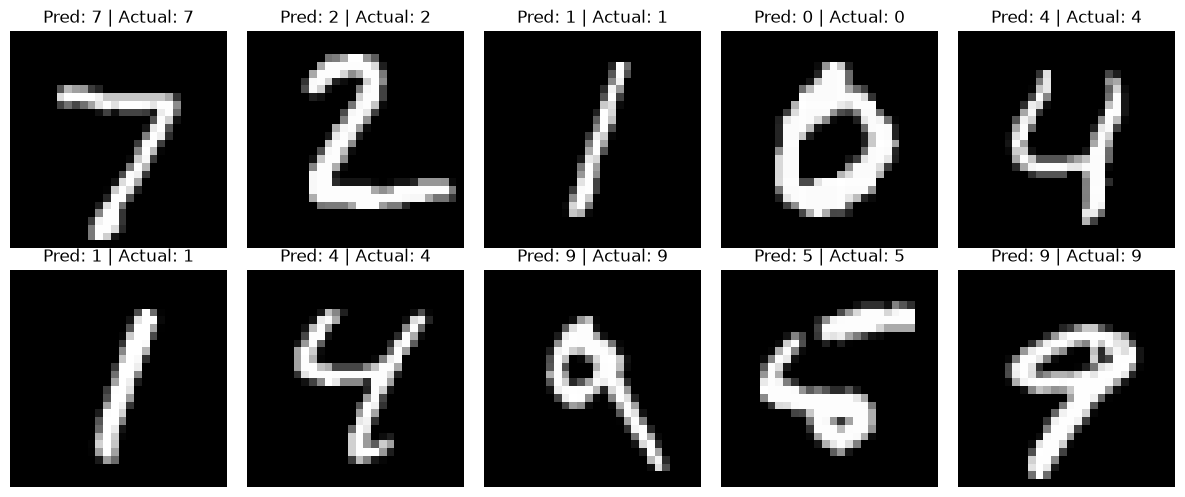

In [47]:
plt.figure(figsize=(12, 5))

for i in range(10):
    prediction = loaded_model.predict(
        x_test[i:i+1],
        verbose=0
    )

    predicted = np.argmax(prediction)
    actual = np.argmax(y_test[i])

    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Pred: {predicted} | Actual: {actual}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [48]:
%pip install streamlit streamlit-drawable-canvas pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 3.9 MB/s  0:00:023.9 MB/s eta 0:00:0101
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 3.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 3.8 MB/s  0:00:02a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 3.8 MB/s  0:00:09 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 3.8 MB/s  0:00:02m 3.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [streamlit-drawable-canvas]11/13 [streamlit]
Note: you may need to restart the kernel to use updated packages.
